Summarize organization by ranking each chosen item's distance among the available alternatives. Align a precomputed distance matrix, calculate participant summaries and save the figure.

## Settings


In [1]:
#| code-summary: "1 — Set the parameters for this run"

# Working directory (None discovers the enclosing Git project).
project_root = None


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/distrank"


# Analysis and uncertainty settings
confidence_level = 0.95
distance_matrix_path = "data/Dupertuys2026_semantic_distances.npy"
distance_path = None  # Accept the earlier preview name when supplied.
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "distrank"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None
trial_queries = ["data['list_type'] == 1"]
labels = ["Mixed lists"]
selection_label = "Mixed lists"


# Figure appearance
color_cycle = None
ylim = None
yticks = None

complete_lists_only = False

contrast_name = None

# Artifact formats and exact local provenance
figure_formats = ["png"]
provenance_dir = None
provenance_source_paths = []
notebook_source = ""

# Explicit participant-bootstrap settings
bootstrap_method = "BCa"
n_resamples = 9999
bootstrap_seed = 0


In [3]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "main"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths)
        + [distance_path or distance_matrix_path],
        revision=revision, base_dir=project_root,
    )


In [4]:
#| code-summary: "3 — Import packages"

import csv
import sys
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

import jaxcmr
from jaxcmr.analyses.distrank import percentile_rank, plot_distrank, subject_distrank
from jaxcmr.analyses.distrank import test_distrank as run_test_distrank
from jaxcmr.helpers import find_project_root, resolve_project_path, generate_trial_mask, load_data, save_figure

from jaxcmr.provenance import capture_notebook


## Align items with the distance matrix


In [5]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

if project_root is not None:
    root_path = resolve_project_path(project_root, Path.cwd())
elif "google.colab" in sys.modules:
    root_path = Path.cwd()
else:
    try:
        root_path = Path(find_project_root())
    except FileNotFoundError:
        root_path = Path.cwd()
print("Project directory:", root_path)

np.random.seed(plot_seed)
output_dir = resolve_project_path(output_dir, root_path)
figure_dir = resolve_project_path(figure_dir, root_path) if figure_dir is not None else output_dir
output_dir.mkdir(parents=True, exist_ok=True)
distance_matrix_path = resolve_project_path(distance_path or distance_matrix_path, root_path)

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_paths = [resolve_project_path(path, root_path) for path in input_paths]
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [6]:
#| code-summary: "4a — Capture parameters, inputs and exact local source"
provenance = capture_notebook(
    {name: globals()[name] for name in ['project_root', 'bootstrap_method', 'bootstrap_seed', 'color_cycle', 'complete_lists_only', 'confidence_level', 'contrast_name', 'data_labels', 'data_path', 'data_paths', 'distance_matrix_path', 'distance_path', 'figure_dir', 'figure_formats', 'figure_str', 'labels', 'max_subjects', 'n_resamples', 'notebook_source', 'output_dir', 'plot_seed', 'provenance_dir', 'provenance_source_paths', 'selection_label', 'trial_queries', 'trial_query', 'ylim', 'yticks']},
    resolve_project_path(provenance_dir, root_path) if provenance_dir is not None else resolve_project_path(output_dir, root_path) / "provenance",
    [Path(jaxcmr.__file__).parent, *map(Path, provenance_source_paths)],
    notebook_source=notebook_source,
    base_dir=root_path,
)
print("Provenance:", provenance["path"])


In [7]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [8]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed lists: 246 lists, 123 participants


CMR / Mixed lists: 2460 lists, 123 participants
Source-only eCMR / Mixed lists: 2460 lists, 123 participants
Broader eCMR / Mixed lists: 2460 lists, 123 participants


In [9]:
#| code-summary: "7 — Load semantic distances or derive them from supplied features"

trial_mask = trial_masks[0]

distance_matrix = jnp.asarray(np.load(distance_matrix_path))


In [10]:
#| code-summary: "8 — Check item alignment and required within-list distances"

matrix = np.asarray(distance_matrix)
if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
    raise ValueError("Supply a square distance matrix indexed by item ID minus one.")
for dataset, masks in zip(datasets, masks_by_dataset):
    for ids in np.asarray(dataset["pres_itemids"])[np.logical_or.reduce(masks)].astype(
        int
    ):
        ids = ids[ids > 0]
        distances = matrix[np.ix_(ids - 1, ids - 1)]
        if not np.isfinite(distances[~np.eye(len(ids), dtype=bool)]).all():
            raise ValueError("Some within-list alternatives have missing distances.")


In [11]:
#| code-summary: "9 — Inspect distances for selected item identities"

row = int(np.flatnonzero(np.asarray(trial_mask))[0])
item_ids = np.asarray(data["pres_itemids"])[row].astype(int)
item_ids = item_ids[item_ids > 0][:5]
print(
    tabulate(
        np.column_stack([item_ids, matrix[np.ix_(item_ids - 1, item_ids - 1)]]),
        headers=["Item ID", *item_ids],
        floatfmt=".3f",
    )
)


  Item ID       32       66     48       60       25
---------  -------  -------  -----  -------  -------
   32.000  nan        0.345  0.587    0.588    0.598
   66.000    0.345  nan      0.623    0.440    0.549
   48.000    0.587    0.623  0.000    0.662    0.561
   60.000    0.588    0.440  0.662  nan        0.575
   25.000    0.598    0.549  0.561    0.575  nan


## Work through a rank


In [12]:
#| code-summary: "10 — Rank an eligible transition by item distance"

eligible_rows = np.flatnonzero(
    np.asarray(trial_mask) & ((np.asarray(data["recalls"]) > 0).sum(axis=1) >= 2)
)
if not len(eligible_rows):
    print(
        "No eligible transition to illustrate; distance-rank scores are undefined for this selection."
    )
else:
    row = int(eligible_rows[0])
    recall = np.asarray(data["recalls"])[row].astype(int)
    recall = recall[recall > 0]
    previous_position, next_position = recall[:2]
    trial_ids = np.asarray(data["pres_itemids"])[row].astype(int)
    previous_id = trial_ids[previous_position - 1]
    next_id = trial_ids[next_position - 1]
    candidates = trial_ids[(trial_ids > 0) & (trial_ids != previous_id)]
    distances = distance_matrix[previous_id - 1, candidates - 1]
    chosen_distance = distance_matrix[previous_id - 1, next_id - 1]
    order = np.argsort(distances)
    print(
        tabulate(
            np.column_stack(
                [
                    candidates[order],
                    np.asarray(distances)[order],
                    (candidates == next_id)[order],
                ]
            ),
            headers=["Candidate item ID", "Distance", "Chosen"],
            floatfmt=".4g",
        )
    )
    print(
        f"Chosen-transition score: {float(percentile_rank(chosen_distance, distances)):.3f}"
    )


  Candidate item ID    Distance    Chosen
-------------------  ----------  --------
                 32      0.3454         0
                 60      0.4404         0
                 16      0.4689         0
                 44      0.4726         0
                 59      0.5337         0
                 25      0.5494         0
                 23      0.5707         1
                 48      0.6233         0
                 73      0.6277         0
                 22      0.6464         0
                 41      0.6534         0


Chosen-transition score: 0.400


## Summarize and save


In [13]:
#| code-summary: "11 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


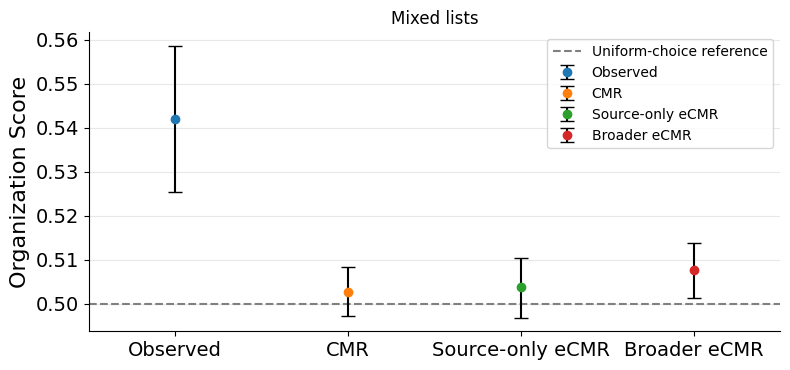

In [14]:
#| code-summary: "12 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for panel_index, (ax, panel) in enumerate(zip(axes.ravel(), panels)):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_distrank(
        panel_data,
        panel_masks,
        distance_matrix=distance_matrix,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        bootstrap_method=bootstrap_method,
        n_resamples=n_resamples, bootstrap_seed=bootstrap_seed + panel_index * len(panel_data),
        axis=ax,
    )
    ax.axhline(0.5, color="grey", linestyle="--", label="Uniform-choice reference")
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str, formats=figure_formats)


In [15]:
#| code-summary: "13 — Calculate participant ranks and report the existing statistical test"

participant_rows = []
for dataset, dataset_label, condition_masks in zip(
    datasets, input_labels, masks_by_dataset
):
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_scores = np.asarray(
            subject_distrank(dataset, condition_mask, distance_matrix)
        )
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        participant_rows.extend(
            (dataset_label, condition_label, subject, score)
            for subject, score in zip(participant_ids, participant_scores)
        )
        print(
            f"{dataset_label} / {condition_label}: {np.isfinite(participant_scores).sum()} scores; mean {np.nanmean(participant_scores):.3f}"
        )
        print(run_test_distrank(participant_scores))


Observed / Mixed lists: 122 scores; mean 0.542
N=122
Mean factor: 0.5420
t-stat: 4.925 p=0.0000
W-stat: 1953.0 p=0.0000
CMR / Mixed lists: 122 scores; mean 0.503
N=122
Mean factor: 0.5028
t-stat: 0.967 p=0.3354
W-stat: 3353.0 p=0.3086


Source-only eCMR / Mixed lists: 122 scores; mean 0.504
N=122
Mean factor: 0.5038
t-stat: 1.068 p=0.2877
W-stat: 3463.0 p=0.4611
Broader eCMR / Mixed lists: 122 scores; mean 0.508
N=122
Mean factor: 0.5077
t-stat: 2.456 p=0.0155
W-stat: 2814.0 p=0.0166


In [16]:
#| code-summary: "14 — Save participant summaries as CSV"

with (output_dir / "participant_ranks.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["Dataset", "Condition", "Subject", "Rank"])
    writer.writerows(participant_rows)


In [17]:
#| code-summary: "14a — Save explicit participant-bootstrap summaries"
from jaxcmr.analyses.uncertainty import mean_interval
summary_rows = []
groups = list(dict.fromkeys((row[0], row[1]) for row in participant_rows))
for index, (dataset_label, condition_label) in enumerate(groups):
    values = [row[3] for row in participant_rows if row[:2] == (dataset_label, condition_label)]
    group_seed = bootstrap_seed + input_labels.index(dataset_label) + len(input_labels) * condition_labels.index(condition_label)
    interval = mean_interval(values, confidence_level=confidence_level, method=bootstrap_method,
                             n_resamples=n_resamples, seed=group_seed)
    summary_rows.append({"Dataset": dataset_label, "Condition": condition_label, **interval})
with (output_dir / "summary_intervals.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
